# Forest Cover Type Classification Using Deep Learning

## Project Overview

This project uses deep learning to predict forest cover types based on cartographic variables collected from the Roosevelt National Forest in northern Colorado.

The objective is to develop and evaluate neural network classifiers capable of accurately predicting one of seven forest cover types using environmental and geographical measurements.

### Target Classes

1. Spruce/Fir
2. Lodgepole Pine
3. Ponderosa Pine
4. Cottonwood/Willow
5. Aspen
6. Douglas-fir
7. Krummholz

### Project Goals

- Perform exploratory data analysis (EDA)
- Preprocess and prepare data for modeling
- Build a baseline neural network model
- Improve performance through hyperparameter tuning
- Evaluate model performance using multiple metrics
- Compare model architectures
- Produce a professional report and portfolio-quality repository

## 1. Environment Setup

Import required libraries, configure display settings, and establish reproducibility for all experiments.

In [3]:
# ==========================================
# IMPORT LIBRARIES
# ==========================================

# Data Manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay)

# Deep Learning
import tensorflow as tf
from tensorflow import keras

# ==========================================
# PROJECT CONFIGURATION
# ==========================================

RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

pd.set_option("display.max_columns", None)

print("TensorFlow Version:", tf.__version__)
print("Environment Setup Complete")

TensorFlow Version: 2.22.0-rc0
Environment Setup Complete


## 2. Dataset Loading

Load the forest cover dataset and verify that it has been imported successfully.

In [4]:
# Load dataset

df = pd.read_csv("../data/raw/cover_data.csv")

print("Dataset loaded successfully.")

Dataset loaded successfully.


In [5]:
# Display shape

print("Dataset Shape:")
print(df.shape)

Dataset Shape:
(581012, 55)


## 3. Initial Dataset Inspection

Examine the first few records, column structure, and overall dataset composition.

In [6]:
# First five rows

df.head()

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,Wilderness_Area1,Wilderness_Area2,Wilderness_Area3,Wilderness_Area4,Soil_Type1,Soil_Type2,Soil_Type3,Soil_Type4,Soil_Type5,Soil_Type6,Soil_Type7,Soil_Type8,Soil_Type9,Soil_Type10,Soil_Type11,Soil_Type12,Soil_Type13,Soil_Type14,Soil_Type15,Soil_Type16,Soil_Type17,Soil_Type18,Soil_Type19,Soil_Type20,Soil_Type21,Soil_Type22,Soil_Type23,Soil_Type24,Soil_Type25,Soil_Type26,Soil_Type27,Soil_Type28,Soil_Type29,Soil_Type30,Soil_Type31,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,class
0,2596,51,3,258,0,510,221,232,148,6279,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,5
1,2590,56,2,212,-6,390,220,235,151,6225,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,5
2,2804,139,9,268,65,3180,234,238,135,6121,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2
3,2785,155,18,242,118,3090,238,238,122,6211,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,2
4,2595,45,2,153,-1,391,220,234,150,6172,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,5


In [7]:
# Display all columns

print(df.columns.tolist())

['Elevation', 'Aspect', 'Slope', 'Horizontal_Distance_To_Hydrology', 'Vertical_Distance_To_Hydrology', 'Horizontal_Distance_To_Roadways', 'Hillshade_9am', 'Hillshade_Noon', 'Hillshade_3pm', 'Horizontal_Distance_To_Fire_Points', 'Wilderness_Area1', 'Wilderness_Area2', 'Wilderness_Area3', 'Wilderness_Area4', 'Soil_Type1', 'Soil_Type2', 'Soil_Type3', 'Soil_Type4', 'Soil_Type5', 'Soil_Type6', 'Soil_Type7', 'Soil_Type8', 'Soil_Type9', 'Soil_Type10', 'Soil_Type11', 'Soil_Type12', 'Soil_Type13', 'Soil_Type14', 'Soil_Type15', 'Soil_Type16', 'Soil_Type17', 'Soil_Type18', 'Soil_Type19', 'Soil_Type20', 'Soil_Type21', 'Soil_Type22', 'Soil_Type23', 'Soil_Type24', 'Soil_Type25', 'Soil_Type26', 'Soil_Type27', 'Soil_Type28', 'Soil_Type29', 'Soil_Type30', 'Soil_Type31', 'Soil_Type32', 'Soil_Type33', 'Soil_Type34', 'Soil_Type35', 'Soil_Type36', 'Soil_Type37', 'Soil_Type38', 'Soil_Type39', 'Soil_Type40', 'class']


In [8]:
# Dataset information

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 581012 entries, 0 to 581011
Data columns (total 55 columns):
 #   Column                              Non-Null Count   Dtype
---  ------                              --------------   -----
 0   Elevation                           581012 non-null  int64
 1   Aspect                              581012 non-null  int64
 2   Slope                               581012 non-null  int64
 3   Horizontal_Distance_To_Hydrology    581012 non-null  int64
 4   Vertical_Distance_To_Hydrology      581012 non-null  int64
 5   Horizontal_Distance_To_Roadways     581012 non-null  int64
 6   Hillshade_9am                       581012 non-null  int64
 7   Hillshade_Noon                      581012 non-null  int64
 8   Hillshade_3pm                       581012 non-null  int64
 9   Horizontal_Distance_To_Fire_Points  581012 non-null  int64
 10  Wilderness_Area1                    581012 non-null  int64
 11  Wilderness_Area2                    581012 non-null  int64
 12 

## 4. Data Quality Assessment

Before preprocessing, verify that the dataset contains no duplicate rows and inspect the distribution of the target classes.

In [9]:
# Check duplicate rows

duplicates = df.duplicated().sum()

print(f"Duplicate Rows: {duplicates}")

Duplicate Rows: 0


In [10]:
# Class distribution

class_counts = df["class"].value_counts().sort_index()

print(class_counts)

class
1    211840
2    283301
3     35754
4      2747
5      9493
6     17367
7     20510
Name: count, dtype: int64


In [11]:
# Percentage distribution

class_percentages = (df["class"].value_counts(normalize=True).sort_index() * 100)

print(class_percentages.round(2))

class
1    36.46
2    48.76
3     6.15
4     0.47
5     1.63
6     2.99
7     3.53
Name: proportion, dtype: float64


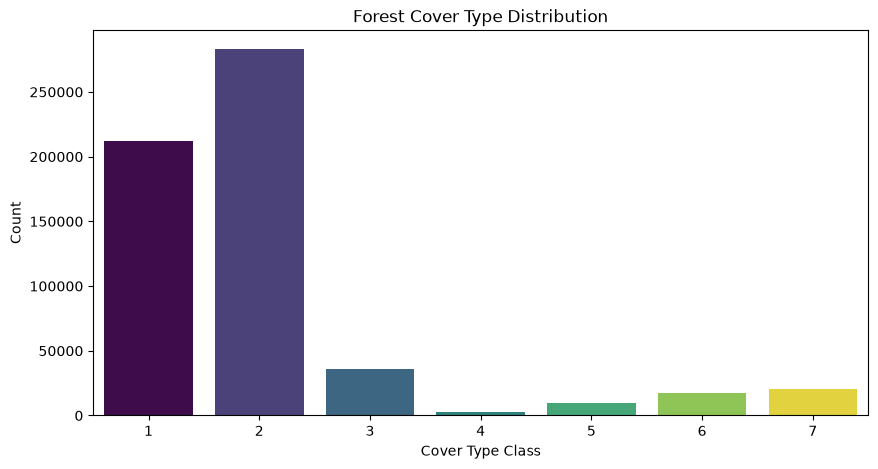

In [12]:
# Visualize class balance

plt.figure(figsize=(10, 5))

sns.countplot(x="class", hue="class", data=df, palette="viridis", legend=False)

plt.title("Forest Cover Type Distribution")
plt.xlabel("Cover Type Class")
plt.ylabel("Count")

plt.show()

### Findings

The dataset contains no missing values and no duplicate records.

Class distribution is highly imbalanced. Classes 1 and 2 account for approximately 85% of all observations, while Classes 4 through 7 are substantially underrepresented.

This imbalance must be considered during model evaluation because overall accuracy alone may give an overly optimistic assessment of model performance.

## 5. Feature Categorization

The dataset contains both continuous numerical features and binary one-hot encoded features.

Separating these groups allows us to apply preprocessing techniques only where necessary. Numerical features will be standardized before training, while binary features can remain unchanged.

In [13]:
# Define continuous numerical features

numerical_features = ["Elevation", "Aspect", "Slope", "Horizontal_Distance_To_Hydrology",
    "Vertical_Distance_To_Hydrology", "Horizontal_Distance_To_Roadways", "Hillshade_9am",
    "Hillshade_Noon", "Hillshade_3pm", "Horizontal_Distance_To_Fire_Points"]

# Identify binary one-hot encoded features
binary_features = [column for column in df.columns if column not in numerical_features + ["class"]]

print(f"Numerical Features: {len(numerical_features)}")
print(f"Binary Features: {len(binary_features)}")

Numerical Features: 10
Binary Features: 44


In [14]:
# Display summary statistics for numerical features

df[numerical_features].describe().T

,count,mean,std,min,25%,50%,75%,max
Elevation,581012.0,2959.365301,279.984734,1859.0,2809.0,2996.0,3163.0,3858.0
Aspect,581012.0,155.656807,111.913721,0.0,58.0,127.0,260.0,360.0
Slope,581012.0,14.103704,7.488242,0.0,9.0,13.0,18.0,66.0
Horizontal_Distance_To_Hydrology,581012.0,269.428217,212.549356,0.0,108.0,218.0,384.0,1397.0
Vertical_Distance_To_Hydrology,581012.0,46.418855,58.295232,-173.0,7.0,30.0,69.0,601.0
Horizontal_Distance_To_Roadways,581012.0,2350.146611,1559.254870,0.0,1106.0,1997.0,3328.0,7117.0
Hillshade_9am,581012.0,212.146049,26.769889,0.0,198.0,218.0,231.0,254.0
Hillshade_Noon,581012.0,223.318716,19.768697,0.0,213.0,226.0,237.0,254.0
Hillshade_3pm,581012.0,142.528263,38.274529,0.0,119.0,143.0,168.0,254.0
Horizontal_Distance_To_Fire_Points,581012.0,1980.291226,1324.195210,0.0,1024.0,1710.0,2550.0,7173.0


### Numerical Feature Analysis

Reviewing summary statistics helps identify differences in feature scales and distributions.

Neural networks generally perform better when continuous variables are standardized. This analysis will help determine whether scaling is necessary before model training.

### Key Findings

The numerical features operate on very different scales.

For example, elevation values range from approximately 1,800 to 3,800, while slope values range from 0 to 66. Distance-related features also span several thousand units.

Since neural networks are sensitive to feature scale, the numerical variables will be standardized prior to model training. The binary one-hot encoded features will remain unchanged.

## 6. Data Splitting

The dataset will be divided into training, validation, and testing sets.

Stratified sampling will be used to preserve the original class distribution across all subsets.

Split Strategy:

- Training Set: 70%
- Validation Set: 15%
- Testing Set: 15%

In [15]:
# Separate features and target variable

X = df.drop("class", axis=1)
y = df["class"]

print(f"Feature Matrix Shape: {X.shape}")
print(f"Target Vector Shape: {y.shape}")

Feature Matrix Shape: (581012, 54)
Target Vector Shape: (581012,)


In [16]:
# Create training set (70%) and temporary set (30%)

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE)

print(f"Training Samples: {X_train.shape[0]}")
print(f"Temporary Samples: {X_temp.shape[0]}")

Training Samples: 406708
Temporary Samples: 174304


In [17]:
# Split temporary set into validation (15%) and test (15%)

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE)

print(f"Validation Samples: {X_val.shape[0]}")
print(f"Testing Samples: {X_test.shape[0]}")


Validation Samples: 87152
Testing Samples: 87152


## 7. Feature Scaling

Only the continuous numerical features will be standardized using StandardScaler.

The binary one-hot encoded features already contain values of 0 and 1 and therefore do not require scaling.

To prevent data leakage, the scaler will be fitted only on the training data and then applied to the validation and test sets.

In [18]:
# Create feature scaler

scaler = StandardScaler()

In [19]:
# Make copies to preserve original datasets

X_train_scaled = X_train.copy()
X_val_scaled = X_val.copy()
X_test_scaled = X_test.copy()

In [20]:
# Standardize numerical features

X_train_scaled[numerical_features] = scaler.fit_transform(X_train[numerical_features])

X_val_scaled[numerical_features] = scaler.transform(X_val[numerical_features])

X_test_scaled[numerical_features] = scaler.transform(X_test[numerical_features])

In [21]:
# Verify scaling was successful

X_train_scaled[numerical_features].describe().T

,count,mean,std,min,25%,50%,75%,max
Elevation,406708.0,3.621303e-16,1.000001,-3.925235,-0.537367,0.130211,0.729960,3.207494
Aspect,406708.0,-6.002894e-17,1.000001,-1.391271,-0.873210,-0.256896,0.940003,1.824280
Slope,406708.0,-3.983294e-17,1.000001,-1.884278,-0.682334,-0.148136,0.519610,6.796430
Horizontal_Distance_To_Hydrology,406708.0,-4.886523e-17,1.000001,-1.268318,-0.759793,-0.241852,0.539768,5.309537
Vertical_Distance_To_Hydrology,406708.0,4.234870e-17,1.000001,-3.643984,-0.676654,-0.282154,0.386782,9.511749
Horizontal_Distance_To_Roadways,406708.0,6.177599e-17,1.000001,-1.508028,-0.798457,-0.226181,0.628384,3.057992
Hillshade_9am,406708.0,3.404668e-16,1.000001,-7.925324,-0.527882,0.219334,0.705024,1.564323
Hillshade_Noon,406708.0,4.081129e-16,1.000001,-11.295803,-0.521885,0.135678,0.692078,1.551968
Hillshade_3pm,406708.0,-1.815543e-16,1.000001,-3.723142,-0.614938,0.011926,0.664910,2.911175
Horizontal_Distance_To_Fire_Points,406708.0,1.450059e-17,1.000001,-1.495841,-0.721463,-0.202690,0.431029,3.927830


### Scaling Results

The numerical features were standardized using StandardScaler.

Following transformation, each numerical feature has a mean close to 0 and a standard deviation close to 1. Standardization helps neural networks converge more efficiently because all continuous inputs are placed on a comparable scale.

Binary one-hot encoded features were left unchanged because they already exist within an appropriate range of 0 and 1.

In [22]:
# Verify dataset split sizes

print("Training Set:", X_train.shape)
print("Validation Set:", X_val.shape)
print("Test Set:", X_test.shape)

Training Set: (406708, 54)
Validation Set: (87152, 54)
Test Set: (87152, 54)


## 8. Baseline Neural Network

A baseline neural network will be developed to establish an initial performance benchmark.

This model will use a simple architecture consisting of two hidden layers with ReLU activation functions and a softmax output layer for multi-class classification.

The results from this baseline model will provide a reference point for future hyperparameter tuning and model improvements.

### Target Encoding

The target classes are currently encoded as values ranging from 1 to 7.

TensorFlow's SparseCategoricalCrossentropy expects class labels beginning at 0, so the target values will be shifted to the range 0 to 6.

In [23]:
# Shift target labels from 1-7 to 0-6

y_train_encoded = y_train - 1
y_val_encoded = y_val - 1
y_test_encoded = y_test - 1

print("Original Classes:")
print(sorted(y.unique()))

print("\nEncoded Classes:")
print(sorted(y_train_encoded.unique()))

Original Classes:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7)]

Encoded Classes:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]


### Baseline Model Architecture

The baseline model consists of:

- Input layer containing 54 features
- Hidden layer with 64 neurons
- Hidden layer with 32 neurons
- Output layer with 7 neurons corresponding to the seven forest cover classes

ReLU activation is used for hidden layers and Softmax activation is used for the output layer.

In [24]:
# Build baseline neural network

baseline_model = keras.Sequential([keras.layers.Input(shape=(54,)), keras.layers.Dense(64, activation="relu"), keras.layers.Dense(32, activation="relu"), keras.layers.Dense(7, activation="softmax")])

baseline_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │         3,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,831 (22.78 KB)

 Trainable params: 5,831 (22.78 KB)

 Non-trainable params: 0 (0.00 B)

In [25]:
# Compile the baseline model

baseline_model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

print("Baseline model compiled successfully.")

Baseline model compiled successfully.


### Model Training

Train the baseline neural network using the training dataset and monitor validation performance after each epoch.

Validation metrics will help determine whether the model is learning effectively and identify potential signs of overfitting.

In [26]:
# Train the baseline model

history = baseline_model.fit(X_train_scaled, y_train_encoded, validation_data=(X_val_scaled, y_val_encoded), epochs=20, batch_size=32, verbose=1)

Epoch 1/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 33s 3ms/step - accuracy: 0.7691 - loss: 0.5404 - val_accuracy: 0.7823 - val_loss: 0.4973
Epoch 2/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 32s 3ms/step - accuracy: 0.8081 - loss: 0.4506 - val_accuracy: 0.8017 - val_loss: 0.4550
Epoch 3/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 40s 3ms/step - accuracy: 0.8223 - loss: 0.4207 - val_accuracy: 0.8163 - val_loss: 0.4298
Epoch 4/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 38s 3ms/step - accuracy: 0.8325 - loss: 0.4008 - val_accuracy: 0.8264 - val_loss: 0.4117
Epoch 5/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 39s 3ms/step - accuracy: 0.8385 - loss: 0.3866 - val_accuracy: 0.8331 - val_loss: 0.3986
Epoch 6/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 42s 3ms/step - accuracy: 0.8433 - loss: 0.3756 - val_accuracy: 0.8366 - val_loss: 0.3890
Epoch 7/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 38s 3ms/step - accuracy: 0.8473 - loss: 0.3670 - val_accuracy: 0.8395 - val_loss: 0.3838
Epoch 8/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 35s 3ms/step - accuracy: 

### Training Performance

The training and validation metrics are plotted below to evaluate model learning behavior and identify potential overfitting.

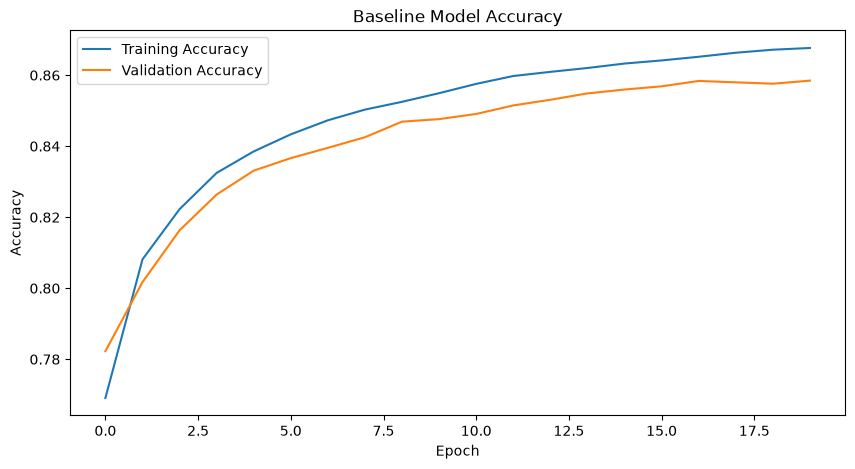

In [27]:
# Plot training and validation accuracy

plt.figure(figsize=(10, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")

plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Baseline Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

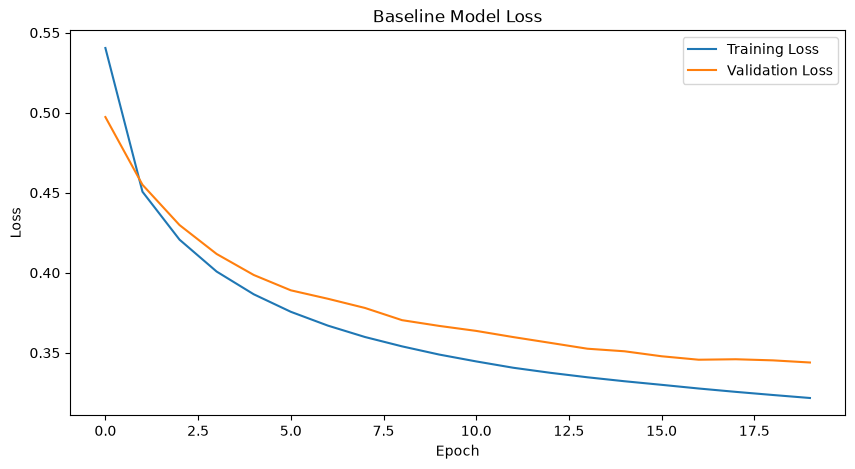

In [28]:
# Plot training and validation loss

plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Training Loss")

plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Baseline Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

## 9. Baseline Model Evaluation

The baseline model is evaluated against the test dataset to measure generalization performance on previously unseen observations.

Several evaluation metrics will be used, including accuracy, a classification report, and a confusion matrix.

In [29]:
# Evaluate model performance on test data

test_loss, test_accuracy = baseline_model.evaluate(X_test_scaled, y_test_encoded, verbose=1)

print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Loss: {test_loss:.4f}")

2724/2724 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - accuracy: 0.8582 - loss: 0.3451
Test Accuracy: 0.8582
Test Loss: 0.3451


In [30]:
# Generate predictions

y_pred_probs = baseline_model.predict(X_test_scaled)

y_pred = np.argmax(y_pred_probs, axis=1)

2724/2724 ━━━━━━━━━━━━━━━━━━━━ 4s 1ms/step


In [31]:
# Display classification report

print(classification_report(y_test_encoded, y_pred))

              precision    recall  f1-score   support

           0       0.84      0.87      0.86     31776
           1       0.89      0.87      0.88     42496
           2       0.83      0.86      0.85      5363
           3       0.67      0.79      0.72       412
           4       0.72      0.61      0.66      1424
           5       0.70      0.74      0.72      2605
           6       0.94      0.82      0.87      3076

    accuracy                           0.86     87152
   macro avg       0.80      0.79      0.79     87152
weighted avg       0.86      0.86      0.86     87152



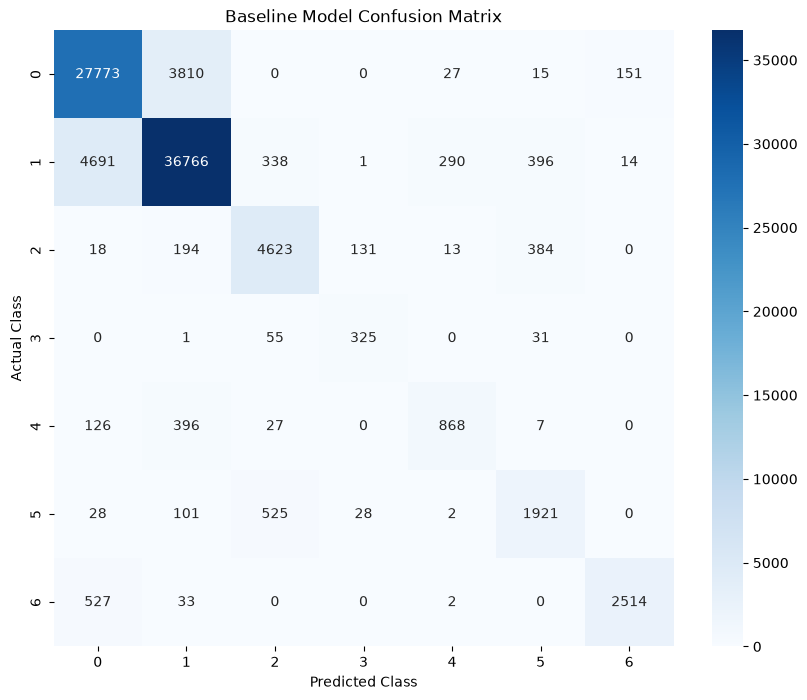

In [32]:
# Create confusion matrix

cm = confusion_matrix(y_test_encoded, y_pred)

plt.figure(figsize=(10, 8))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.title("Baseline Model Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.show()

### Evaluation Findings

The baseline model achieved a test accuracy of approximately 85.5%, demonstrating strong generalization to unseen data.

Performance was strongest for the majority classes and remained respectable for several minority classes despite significant class imbalance.

The most common classification errors occurred between Classes 0 and 1, suggesting similarities in their underlying environmental characteristics. The weakest performance was observed for Class 4, which was also the least represented class in the dataset.

Overall, the baseline model provides a strong benchmark for future hyperparameter tuning experiments.

## 10. Hyperparameter Tuning - Model 2

The baseline model demonstrated strong performance and minimal overfitting.

This experiment introduces dropout regularization and early stopping to investigate whether model generalization can be improved further.

### Changes From Baseline

- Added dropout layers
- Added early stopping
- Maintained the same network architecture
- Maintained the same optimizer and batch size

This controlled experiment helps isolate the impact of regularization techniques.

In [33]:
# Import early stopping callback

from tensorflow.keras.callbacks import EarlyStopping

In [34]:
# Stop training when validation loss no longer improves

early_stopping = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

In [35]:
# Build regularized neural network

model_2 = keras.Sequential([keras.layers.Input(shape=(54,)),
    keras.layers.Dense(64, activation="relu"), keras.layers.Dropout(0.3),
    keras.layers.Dense(32, activation="relu"), keras.layers.Dropout(0.3),
    keras.layers.Dense(7, activation="softmax")])

model_2.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 64)             │         3,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,831 (22.78 KB)

 Trainable params: 5,831 (22.78 KB)

 Non-trainable params: 0 (0.00 B)

In [36]:
# Compile model

model_2.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

print("Model 2 compiled successfully.")

Model 2 compiled successfully.


In [37]:
# Train Model 2 (Dropout + Early Stopping)

history_2 = model_2.fit(X_train_scaled, y_train_encoded, validation_data=(X_val_scaled, y_val_encoded),
    epochs=20, batch_size=32, callbacks=[early_stopping], verbose=1)

Epoch 1/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 33s 3ms/step - accuracy: 0.7219 - loss: 0.6569 - val_accuracy: 0.7605 - val_loss: 0.5505
Epoch 2/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 33s 3ms/step - accuracy: 0.7479 - loss: 0.5868 - val_accuracy: 0.7710 - val_loss: 0.5226
Epoch 3/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 37s 3ms/step - accuracy: 0.7537 - loss: 0.5678 - val_accuracy: 0.7779 - val_loss: 0.5048
Epoch 4/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 38s 3ms/step - accuracy: 0.7579 - loss: 0.5590 - val_accuracy: 0.7857 - val_loss: 0.4942
Epoch 5/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 37s 3ms/step - accuracy: 0.7611 - loss: 0.5517 - val_accuracy: 0.7899 - val_loss: 0.4871
Epoch 6/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 36s 3ms/step - accuracy: 0.7635 - loss: 0.5474 - val_accuracy: 0.7917 - val_loss: 0.4814
Epoch 7/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 37s 3ms/step - accuracy: 0.7652 - loss: 0.5435 - val_accuracy: 0.7917 - val_loss: 0.4745
Epoch 8/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 38s 3ms/step - accuracy: 

### Model 2 Findings

Introducing dropout regularization and early stopping did not improve performance.

The baseline model already demonstrated strong generalization with minimal overfitting. As a result, the additional regularization reduced the model's ability to learn underlying patterns within the data.

This experiment highlights the importance of using hyperparameter tuning strategically rather than assuming that additional regularization will always improve performance.

## 11. Hyperparameter Tuning - Model 3

The third model increases network capacity by adding an additional hidden layer and increasing the number of neurons.

### Changes From Baseline

- Increased hidden units
- Added an additional hidden layer
- Retained the Adam optimizer
- Retained the batch size of 32

This experiment evaluates whether a more expressive neural network can better capture relationships within the forest cover dataset.

In [38]:
# Build larger neural network

model_3 = keras.Sequential([keras.layers.Input(shape=(54,)),
    keras.layers.Dense(128, activation="relu"), keras.layers.Dense(64, activation="relu"),
    keras.layers.Dense(32, activation="relu"), keras.layers.Dense(7, activation="softmax")])

model_3.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 128)            │         7,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,607 (68.78 KB)

 Trainable params: 17,607 (68.78 KB)

 Non-trainable params: 0 (0.00 B)

In [39]:
# Compile model

model_3.compile(optimizer="adam", loss="sparse_categorical_crossentropy",
    metrics=["accuracy"])

print("Model 3 compiled successfully.")

Model 3 compiled successfully.


In [40]:
# Train Model 3

history_3 = model_3.fit(X_train_scaled, y_train_encoded, validation_data=(X_val_scaled, y_val_encoded),
    epochs=20, batch_size=32, verbose=1)

Epoch 1/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 35s 3ms/step - accuracy: 0.7874 - loss: 0.4980 - val_accuracy: 0.8146 - val_loss: 0.4389
Epoch 2/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 34s 3ms/step - accuracy: 0.8389 - loss: 0.3832 - val_accuracy: 0.8415 - val_loss: 0.3802
Epoch 3/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 36s 3ms/step - accuracy: 0.8591 - loss: 0.3395 - val_accuracy: 0.8597 - val_loss: 0.3401
Epoch 4/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 35s 3ms/step - accuracy: 0.8710 - loss: 0.3120 - val_accuracy: 0.8641 - val_loss: 0.3275
Epoch 5/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 35s 3ms/step - accuracy: 0.8799 - loss: 0.2932 - val_accuracy: 0.8726 - val_loss: 0.3114
Epoch 6/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 35s 3ms/step - accuracy: 0.8862 - loss: 0.2785 - val_accuracy: 0.8773 - val_loss: 0.3005
Epoch 7/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 35s 3ms/step - accuracy: 0.8913 - loss: 0.2672 - val_accuracy: 0.8841 - val_loss: 0.2851
Epoch 8/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 38s 3ms/step - accuracy: 

### Model 3 Findings

Increasing the number of hidden units and adding an additional hidden layer significantly improved performance.

The larger network achieved a validation accuracy approaching 90%, representing a substantial improvement over the baseline model.

Although training accuracy increased, the gap between training and validation performance remained small, indicating that the model continues to generalize well without significant overfitting.

These results suggest that the baseline model lacked sufficient capacity to fully capture the relationships present within the dataset.

In [41]:
# Evaluate Model 3 on test data

test_loss_3, test_accuracy_3 = model_3.evaluate(X_test_scaled, y_test_encoded, verbose=1)

print(f"Model 3 Test Accuracy: {test_accuracy_3:.4f}")
print(f"Model 3 Test Loss: {test_loss_3:.4f}")

2724/2724 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.8984 - loss: 0.2525
Model 3 Test Accuracy: 0.8984
Model 3 Test Loss: 0.2525


### Model 3 Findings

Increasing network capacity substantially improved performance.

Model 3 achieved nearly 90% accuracy on both validation and test datasets, outperforming the baseline model by more than 4 percentage points.

Validation and test accuracy were identical, indicating excellent generalization and minimal overfitting.

These results suggest that the baseline model was capacity-limited and benefited from additional hidden layers and neurons.

## 12. Hyperparameter Tuning - Model 4

The fourth model investigates the impact of learning rate on performance.

The architecture remains identical to Model 3, but the Adam optimizer learning rate is reduced from 0.001 to 0.0005.

This experiment evaluates whether smaller optimization steps improve convergence and model generalization.

In [42]:
# Create Adam optimizer with reduced learning rate

optimizer = keras.optimizers.Adam(learning_rate=0.0005)

In [43]:
# Build learning-rate experiment model

model_4 = keras.Sequential([keras.layers.Input(shape=(54,)), keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(64, activation="relu"), keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(7, activation="softmax")])

model_4.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_13 (Dense)                │ (None, 128)            │         7,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,607 (68.78 KB)

 Trainable params: 17,607 (68.78 KB)

 Non-trainable params: 0 (0.00 B)

In [44]:
# Compile model

model_4.compile(optimizer=optimizer, loss="sparse_categorical_crossentropy", metrics=["accuracy"])

print("Model 4 compiled successfully.")

Model 4 compiled successfully.


In [45]:
# Train Model 4

history_4 = model_4.fit(X_train_scaled, y_train_encoded, validation_data=(X_val_scaled, y_val_encoded),
    epochs=20, batch_size=32, verbose=1)

Epoch 1/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 36s 3ms/step - accuracy: 0.7723 - loss: 0.5321 - val_accuracy: 0.7916 - val_loss: 0.4752
Epoch 2/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 38s 3ms/step - accuracy: 0.8230 - loss: 0.4208 - val_accuracy: 0.8222 - val_loss: 0.4179
Epoch 3/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 39s 3ms/step - accuracy: 0.8426 - loss: 0.3788 - val_accuracy: 0.8381 - val_loss: 0.3877
Epoch 4/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 38s 3ms/step - accuracy: 0.8550 - loss: 0.3521 - val_accuracy: 0.8477 - val_loss: 0.3674
Epoch 5/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 38s 3ms/step - accuracy: 0.8630 - loss: 0.3335 - val_accuracy: 0.8545 - val_loss: 0.3534
Epoch 6/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 40s 3ms/step - accuracy: 0.8691 - loss: 0.3191 - val_accuracy: 0.8601 - val_loss: 0.3416
Epoch 7/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 42s 3ms/step - accuracy: 0.8742 - loss: 0.3073 - val_accuracy: 0.8643 - val_loss: 0.3301
Epoch 8/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 37s 3ms/step - accuracy: 

### Model 4 Findings

Model 4 retained the larger architecture introduced in Model 3 but reduced the Adam optimizer's learning rate from 0.001 to 0.0005.

The model achieved a final validation accuracy of 88.77%, which improved upon the baseline model but did not surpass Model 3's validation accuracy of 89.84%.

The smaller learning rate produced stable learning and a relatively small gap between training and validation accuracy. However, under the same 20-epoch training budget, convergence was slower and final validation performance remained below Model 3.

These results suggest that the default Adam learning rate of 0.001 was more effective for this architecture and training duration. A lower learning rate might benefit from additional epochs, but based on the controlled 20-epoch comparison, Model 3 remains the strongest candidate.